In [1]:
import os
import re
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set scanpy visual & output settings
sc.settings.verbosity = 3
sc.settings.set_figure_params(dpi=150, facecolor='white')

# Ensure output figure directory exists using absolute path
fig_dir = os.path.expanduser("~/FYP_Regeneration/results/figures/axolotl/")
os.makedirs(fig_dir, exist_ok=True)
sc.settings.figdir = fig_dir

# Absolute path to raw file
input_path = os.path.expanduser("~/FYP_Regeneration/data/axolotl/processed/GSE106269_Table_S7.csv.gz")
print(f"Loading GSE106269 expression matrix from:\n{input_path}")

df = pd.read_csv(input_path, compression="gzip", index_col=0)
print("Raw file shape:", df.shape)
print("Row index sample:", df.index[:5].tolist())
print("Column sample:", df.columns[:5].tolist())

# Identify metadata columns (e.g., celltype, timepoint)
non_numeric_cols = []
for col in df.columns:
    converted = pd.to_numeric(df[col], errors='coerce')
    if converted.isna().sum() > 0.5 * len(df):
        non_numeric_cols.append(col)

print(f"Detected {len(non_numeric_cols)} metadata columns: {non_numeric_cols}")

# Separate metadata and numeric expression matrix
meta_df = df[non_numeric_cols] if non_numeric_cols else pd.DataFrame(index=df.index)
expr_df = df.drop(columns=non_numeric_cols).apply(pd.to_numeric, errors='coerce').fillna(0)

# --- FIXED ORIENTATION DETECTION ---
# Don't guess from shape (unreliable). Detect plate/well-style IDs
# (e.g. "axo23.A1B") on each axis instead — that axis is CELLS, not genes.
well_pattern = re.compile(r'^axo\d+\.')

index_is_wells = expr_df.index.astype(str).str.match(well_pattern).mean() > 0.5
columns_are_wells = pd.Series(expr_df.columns.astype(str)).str.match(well_pattern).mean() > 0.5

if index_is_wells and not columns_are_wells:
    print(">> Detected: rows = cells/wells, columns = genes. No transpose needed.")
    X_mat = expr_df.values.astype(np.float32)
    obs_df = meta_df if not meta_df.empty else pd.DataFrame(index=expr_df.index)
    var_df = pd.DataFrame(index=expr_df.columns)
elif columns_are_wells and not index_is_wells:
    print(">> Detected: columns = cells/wells, rows = genes. Transposing.")
    X_mat = expr_df.T.values.astype(np.float32)
    obs_df = pd.DataFrame(index=expr_df.columns)
    var_df = pd.DataFrame(index=expr_df.index)
else:
    # Fallback — neither axis matched the well pattern clearly.
    # Print both axes fully and STOP so you can check manually rather than guessing wrong again.
    raise ValueError(
        "Could not confidently detect orientation from well-ID pattern. "
        "Inspect df.index and df.columns manually before proceeding:\n"
        f"index sample: {expr_df.index[:15].tolist()}\n"
        f"columns sample: {expr_df.columns[:15].tolist()}"
    )

adata = sc.AnnData(X=X_mat, obs=obs_df, var=var_df)
print(adata)
print("Sample gene names (should look like real genes now):", adata.var_names[:10].tolist())
print("Sample cell/obs names:", adata.obs_names[:10].tolist())

# QC metrics — mitochondrial % (adjust prefix if axolotl mito genes are named differently)
adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

# QC Step 1: Filter low-quality cells (now with counts + mito filters added)
n_before = adata.n_obs
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_cells(adata, min_counts=500)
if adata.var["mt"].sum() > 0:
    adata = adata[adata.obs["pct_counts_mt"] < 15].copy()
else:
    print("No genes matched the 'MT-' mitochondrial prefix — skipping mito filter. "
          "Check adata.var_names for the correct axolotl mito-gene prefix if needed.")
print(f"Cells before QC: {n_before} -> after QC: {adata.n_obs}")

# QC Step 2: Remove ribosomal protein genes
ribo_genes = adata.var_names.str.startswith(("RPL", "RPS", "rpl", "rps"))
adata = adata[:, ~ribo_genes].copy()
sc.pp.filter_genes(adata, min_cells=3)

# Save a clean, un-transformed checkpoint object
adata_filtered = adata.copy()

print(f"Cell 1 complete! Clean checkpoint created with {adata_filtered.n_obs} cells x {adata_filtered.n_vars} genes.")

Loading GSE106269 expression matrix from:
/home/ghayyas/FYP_Regeneration/data/axolotl/processed/GSE106269_Table_S7.csv.gz
Raw file shape: (1209, 15288)
Row index sample: ['axo10.A1', 'axo10.A10', 'axo10.A10B', 'axo10.A11', 'axo10.A11B']
Column sample: ['celltype', 'timepoint', '0610011F06RIK', '1110008L16RIK', '1500009C09RIK']
Detected 2 metadata columns: ['celltype', 'timepoint']
>> Detected: rows = cells/wells, columns = genes. No transpose needed.
AnnData object with n_obs × n_vars = 1209 × 15286
    obs: 'celltype', 'timepoint'
Sample gene names (should look like real genes now): ['0610011F06RIK', '1110008L16RIK', '1500009C09RIK', '1700011I03RIK', '1700028P14RIK', '1700065I17RIK', '1700066M21RIK', '1700112E06RIK', '1810011H11RIK', '1810033B17RIK']
Sample cell/obs names: ['axo10.A1', 'axo10.A10', 'axo10.A10B', 'axo10.A11', 'axo10.A11B', 'axo10.A12', 'axo10.A12B', 'axo10.A1B', 'axo10.A2', 'axo10.A3']
Cells before QC: 1209 -> after QC: 1209
filtered out 1354 genes that are detected in

normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
Highly variable genes identified: 5089
computing PCA
    with n_comps=50
    finished (0:00:01)
computing neighbors
    using 'X_pca' with n_pcs = 30


/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:12)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)
running Leiden clustering
    finished: found 9 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
Cluster sizes:
leiden
3    221
4    198
0    177
2    151
5    148
6    135
8     82
1     81
7     16
Name: count, dtype: int64


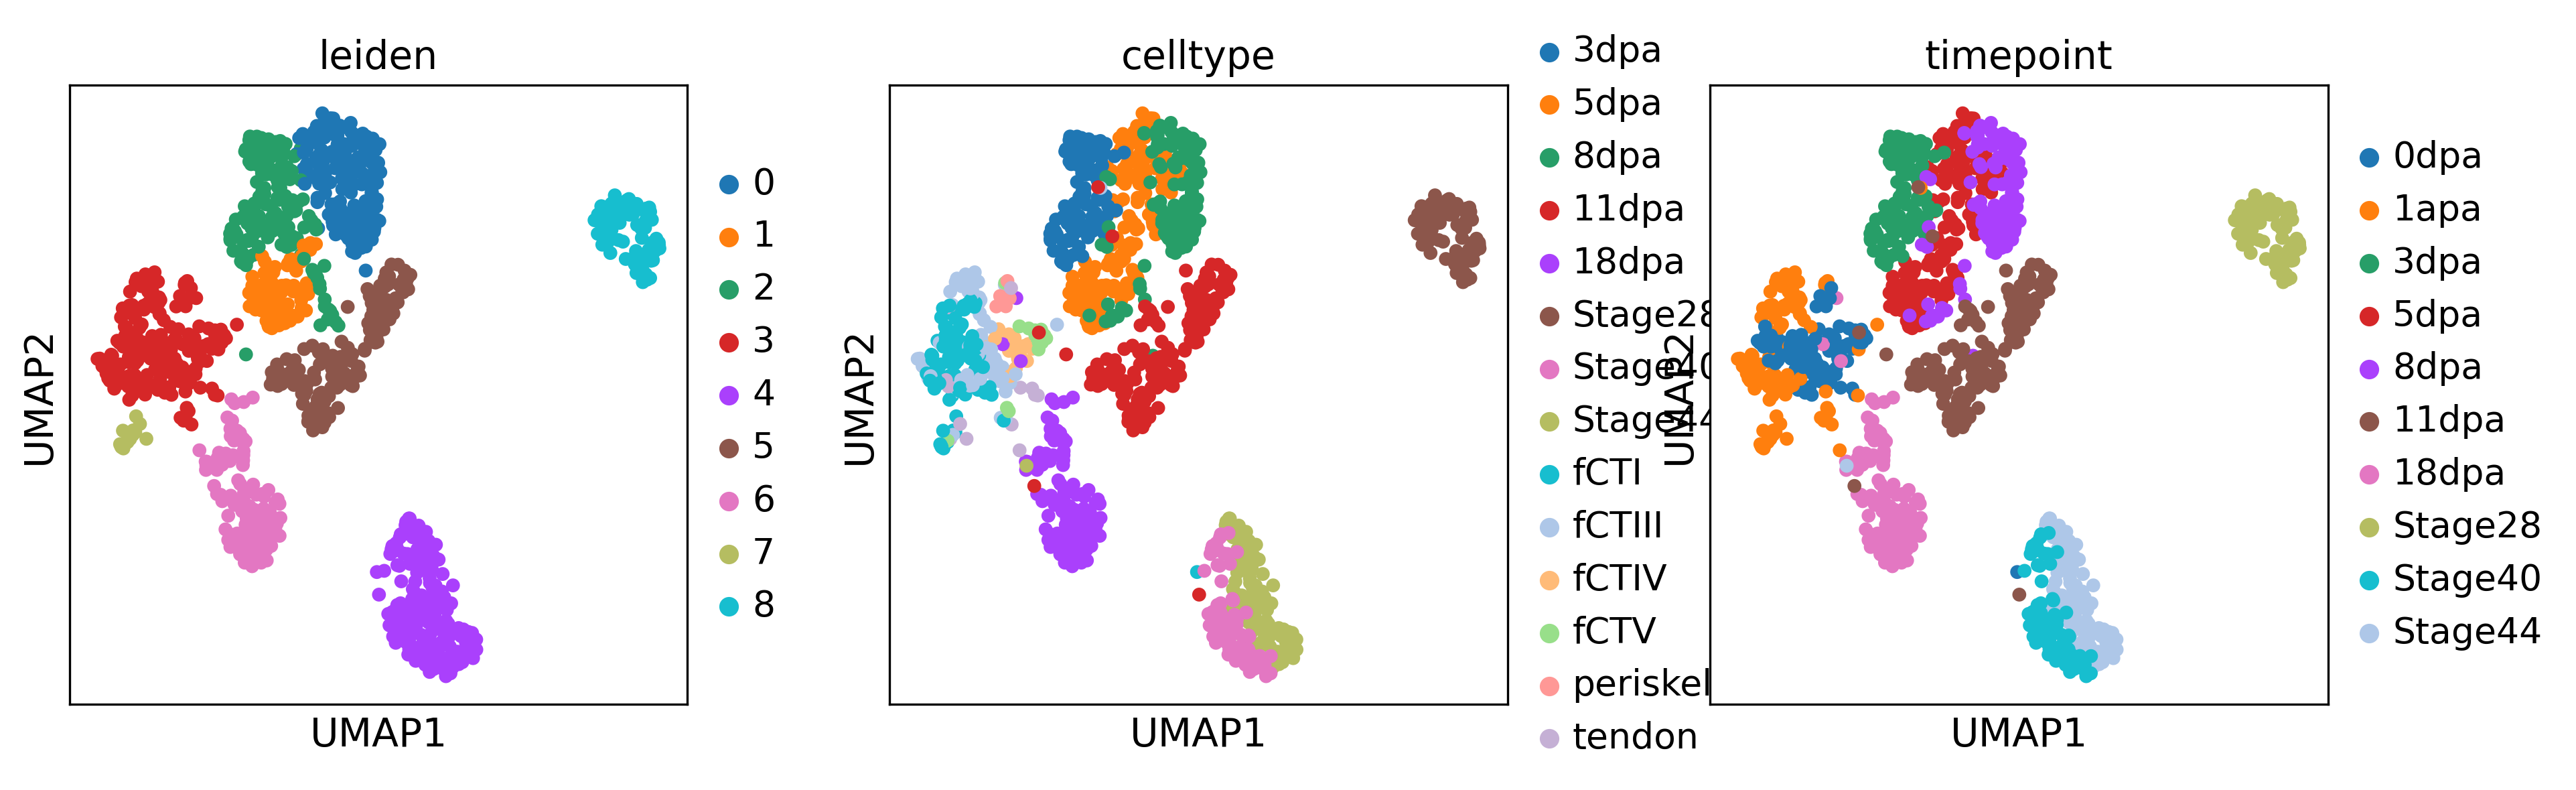

Cell 2 complete! UMAP generated and stored cleanly in adata.


In [2]:
# Always reset to the clean filtered checkpoint to prevent double-transformation
adata = adata_filtered.copy()

# 1. Normalize total counts per cell to 10,000 and log-transform ONCE
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 2. Identify highly variable genes
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.2)
print(f"Highly variable genes identified: {sum(adata.var.highly_variable)}")

# 3. Subset to HVGs for dimensionality reduction (full gene set is kept in `adata` for marker detection later)
adata_hvg = adata[:, adata.var.highly_variable].copy()

# 4. Scale ONLY the HVG subset for PCA/UMAP (leaves primary adata.X unscaled log1p)
adata_scaled = sc.pp.scale(adata_hvg, max_value=10, copy=True)

# 5. Dimensionality reduction & Neighborhood graph on scaled HVG data
sc.tl.pca(adata_scaled, svd_solver='arpack')
sc.pp.neighbors(adata_scaled, n_neighbors=15, n_pcs=30)

# 6. UMAP Embedding & Leiden Clustering on scaled data
sc.tl.umap(adata_scaled)
sc.tl.leiden(adata_scaled, resolution=0.5, flavor="igraph", directed=False)

# Transfer UMAP coordinates and Leiden clusters back to primary unscaled, full-gene adata
adata.obsm['X_umap'] = adata_scaled.obsm['X_umap']
adata.obs['leiden'] = adata_scaled.obs['leiden']

print("Cluster sizes:")
print(adata.obs['leiden'].value_counts())

# 7. Plot and save UMAP
color_vars = ['leiden']
if 'celltype' in adata.obs.columns:
    color_vars.append('celltype')
if 'timepoint' in adata.obs.columns:
    color_vars.append('timepoint')

sc.pl.umap(adata, color=color_vars, save='_axolotl_clusters.png')
print("Cell 2 complete! UMAP generated and stored cleanly in adata.")

Computing marker genes using unscaled log-normalized counts...
ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:07)


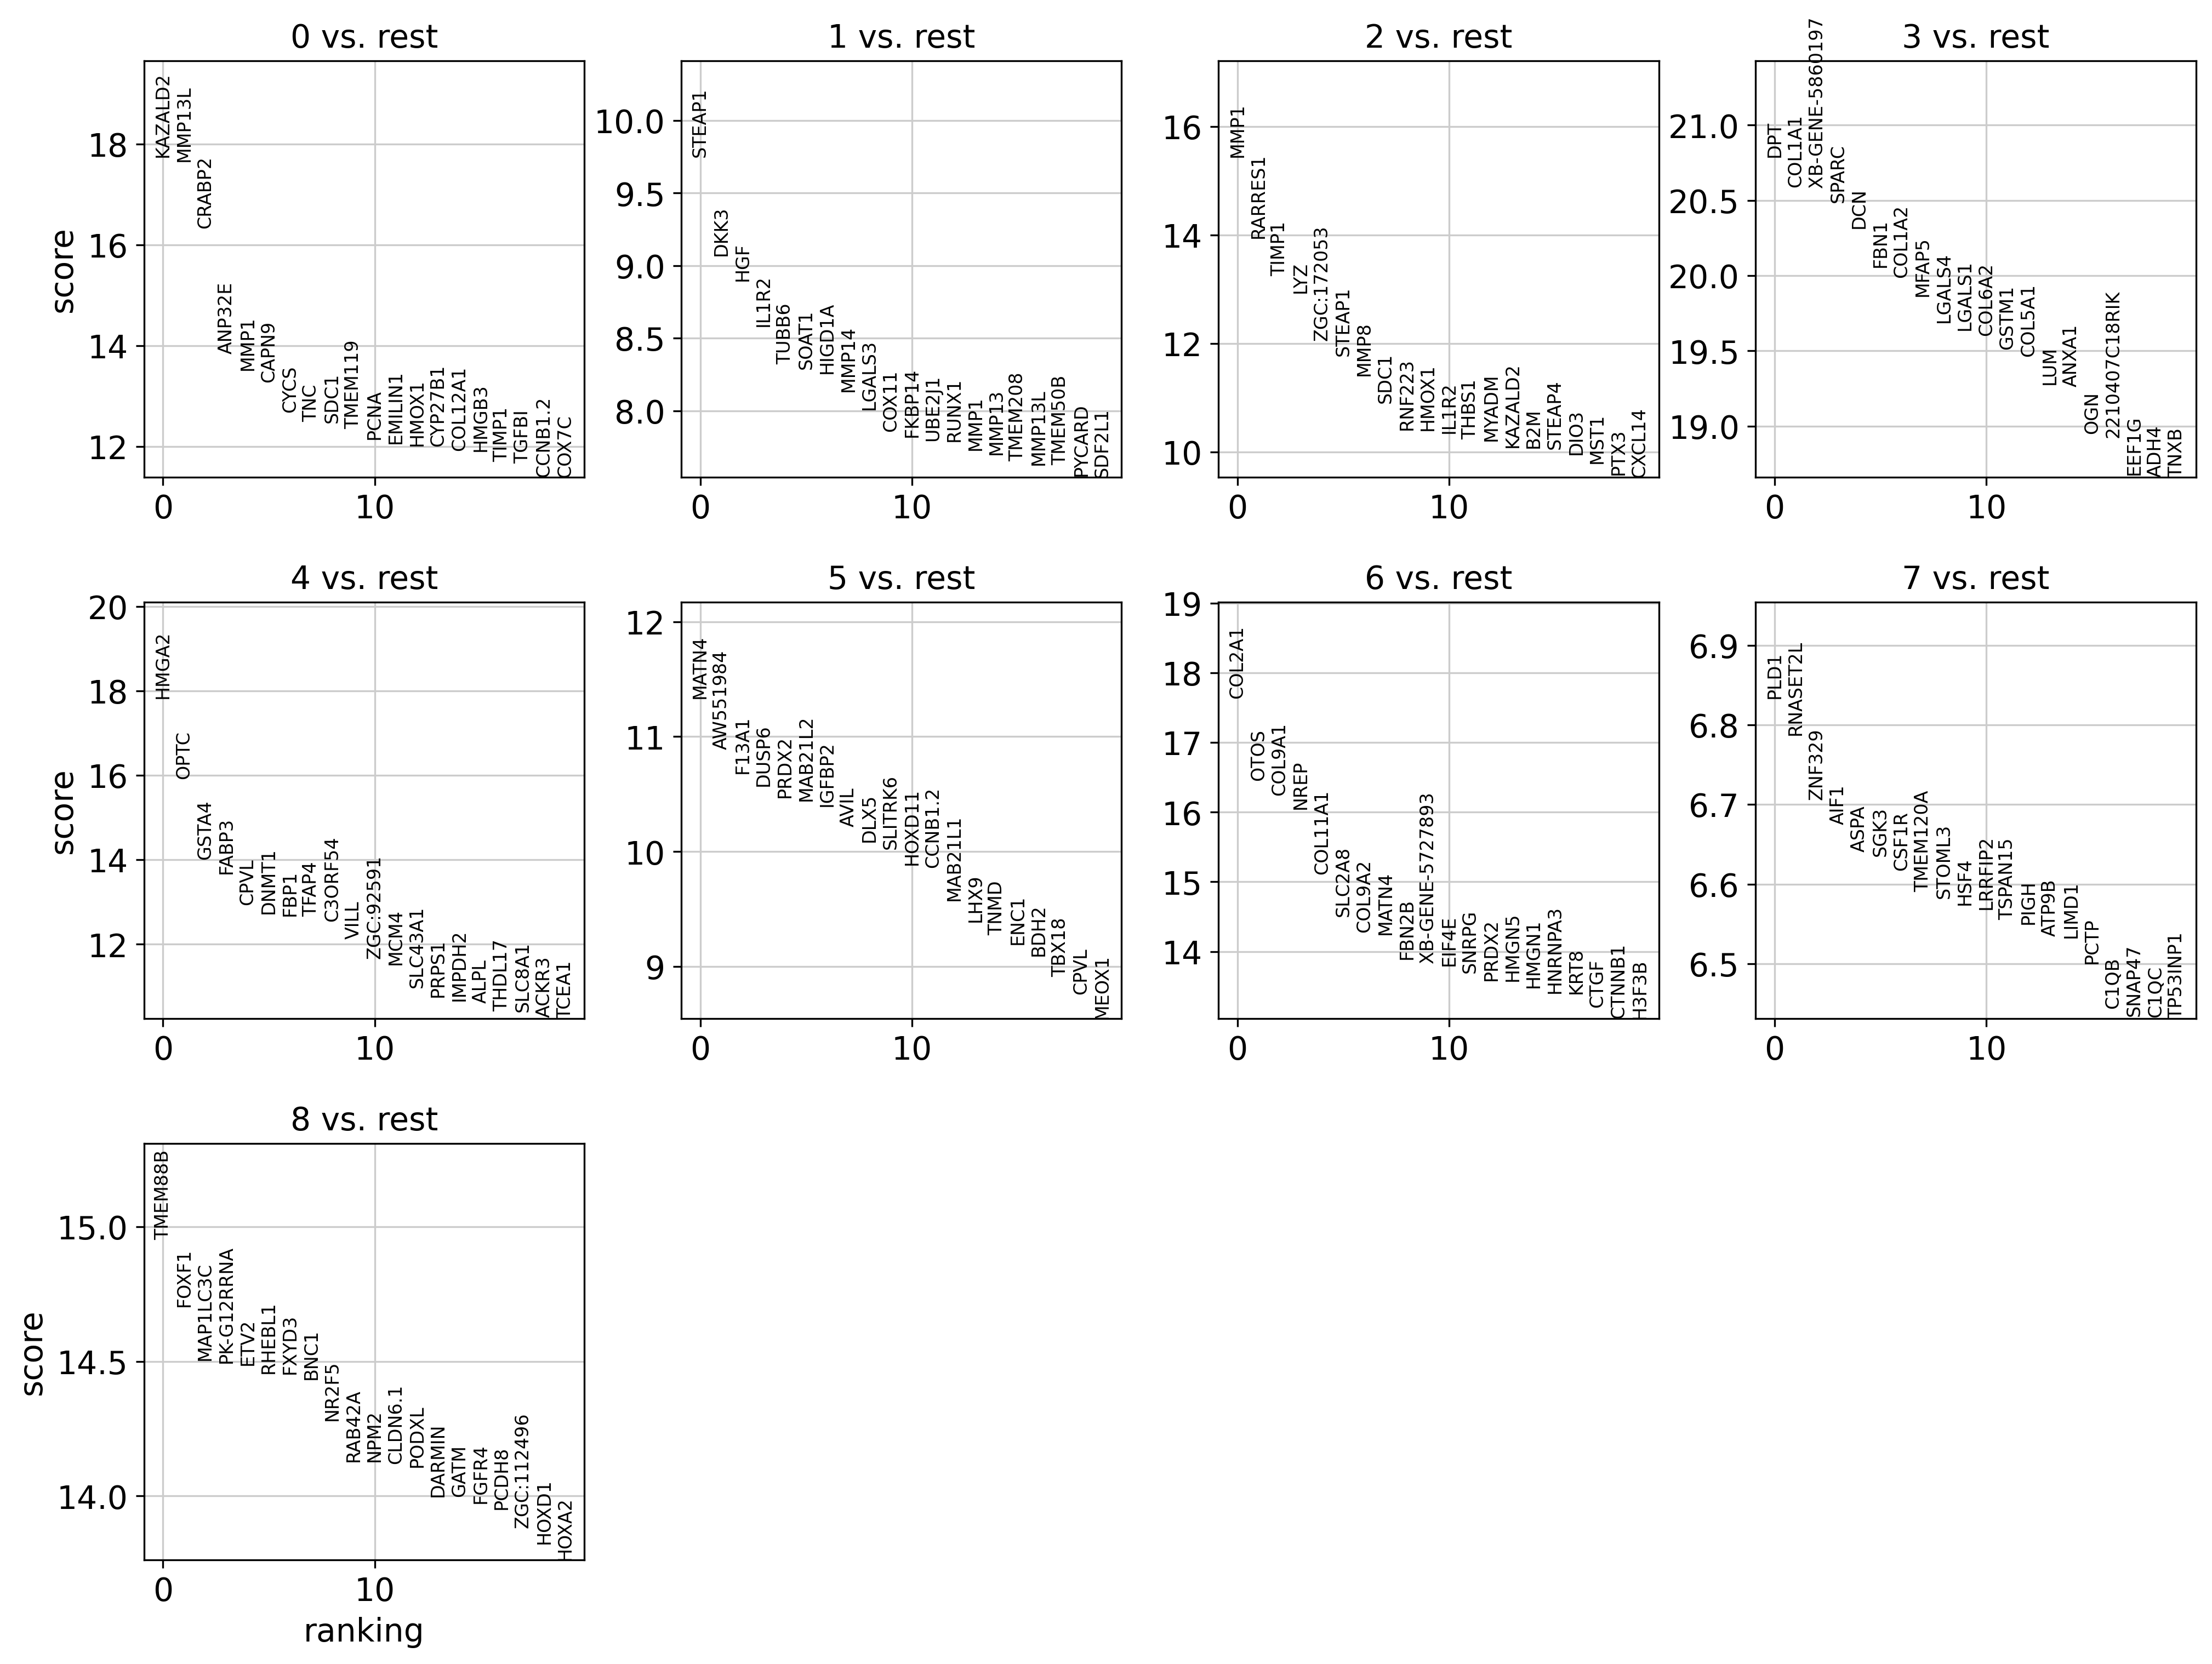

Sample marker genes (should be real gene symbols now): ['KAZALD2', 'MMP13L', 'CRABP2', 'ANP32E', 'MMP1', 'CAPN9', 'CYCS', 'TNC', 'SDC1', 'TMEM119']
Cell 3 complete!
- All markers saved to: /home/ghayyas/FYP_Regeneration/results/tables/axolotl_de_markers_all.csv
- Significant markers saved to: /home/ghayyas/FYP_Regeneration/results/tables/axolotl_de_markers_sig.csv
- Processed AnnData saved to: /home/ghayyas/FYP_Regeneration/data/axolotl/processed/axolotl_processed.h5ad
- Total significant markers found: 16443


In [3]:
# 1. Compute cluster-specific marker genes directly on unscaled log1p, full-gene data
print("Computing marker genes using unscaled log-normalized counts...")
sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon')

# Save top marker gene plot
sc.pl.rank_genes_groups(adata, n_genes=20, sharey=False, save='_axolotl_markers.png')

# 2. Extract marker gene tabular results
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names

markers_list = []
for group in groups:
    df_group = pd.DataFrame({
        'cluster': group,
        'gene': result['names'][group],
        'logfoldchanges': result['logfoldchanges'][group],
        'pvals_adj': result['pvals_adj'][group],
        'scores': result['scores'][group]
    })
    markers_list.append(df_group)

markers_df = pd.concat(markers_list, ignore_index=True)

# Sanity check — confirm real gene symbols made it through
print("Sample marker genes (should be real gene symbols now):", markers_df['gene'].head(10).tolist())

# Filter for significant markers (p_adj < 0.05 and logFC > 0.25)
sig_markers = markers_df[(markers_df['pvals_adj'] < 0.05) & (markers_df['logfoldchanges'] > 0.25)]

# 3. Export CSV tables to results/tables/
tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")
os.makedirs(tables_dir, exist_ok=True)

markers_df.to_csv(os.path.join(tables_dir, "axolotl_de_markers_all.csv"), index=False)
sig_markers.to_csv(os.path.join(tables_dir, "axolotl_de_markers_sig.csv"), index=False)

# 4. Save processed AnnData object to data/axolotl/processed/
output_h5ad = os.path.expanduser("~/FYP_Regeneration/data/axolotl/processed/axolotl_processed.h5ad")
adata.write(output_h5ad, compression="gzip")

print("Cell 3 complete!")
print(f"- All markers saved to: {tables_dir}axolotl_de_markers_all.csv")
print(f"- Significant markers saved to: {tables_dir}axolotl_de_markers_sig.csv")
print(f"- Processed AnnData saved to: {output_h5ad}")
print(f"- Total significant markers found: {len(sig_markers)}")